# Experiment 2 — Parameter Sensitivity, Interactions and Trade-offs

Reference **(N,k,m)=(18387,5,4422)**; N=attempts/family, h=4, GAM/GCV, exact L1, omit bridge.

E2.A thay đổi một tham số; E2.B factorial 2³ và center; E2.C accuracy, stability, matching, runtime/memory.
Ba thư viện synthetic độc lập, nested prefixes trong từng seed; cùng 10.000 COVID targets/config/seed. Đây là sensitivity bổ sung, không phải BO hoặc chọn tham số trên test.

Đọc [README](README.md) để xem quy tắc đã cố định và giới hạn. Notebook chỉ đọc artifacts; không chạy lại toàn bộ jobs.

In [1]:
from pathlib import Path
import json,hashlib,sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/sensitivity/design.py').exists())
OUT = ROOT/'outputs/experiment_2_nonconstant_v2'
progress = json.loads((OUT/'progress.json').read_text())
display({k:v for k,v in progress.items() if k!='notebook_status'})
if progress['status'] != 'complete':
    raise RuntimeError('Experiment 2 is still running; see progress.json and run.log')
def table(name): return pd.read_csv(OUT/(name+'.csv'))
def figure(name): display(Image(filename=str(OUT/'figures'/(name+'.png'))))
sys.path.insert(0,str(ROOT/'experiments/forecasting'))
from model import WINDOW_FILTER
protocol = json.loads((OUT/'protocol.json').read_text())
validation = json.loads((OUT/'validation.json').read_text())
meta = json.loads((OUT/'report_metadata.json').read_text())
def digest(path):
    with Path(path).open('rb') as handle:return hashlib.file_digest(handle,'sha256').hexdigest()
assert protocol['design']['version']==4 and protocol['design']['window_filter']==WINDOW_FILTER=='nonconstant_v2'
assert progress['inputs_unchanged'] and validation['window_filter']==WINDOW_FILTER and validation['constant_history_rows']==0
assert validation['protocol_sha256']==digest(OUT/'protocol.json')
assert meta['analysis_source_sha256']==protocol['source_sha256']['experiments/sensitivity/analysis.py']
for name,sha in protocol['source_sha256'].items():assert digest(OUT/'source_snapshot'/name)==sha,name
for name in ['experiments/sensitivity/library.py','experiments/forecasting/model.py','experiments/forecasting/smoothing.py','experiments/forecasting/neighbors.py']:
    assert digest(ROOT/name)==protocol['source_sha256'][name],name
for path,sha in {**protocol['inputs_sha256'],**(protocol.get('reused_banks') or {}).get('sha256',{})}.items():assert digest(path)==sha,path
for path,sha in meta['artifacts_sha256'].items():assert digest(OUT/path)==sha,path
for folder in (OUT/'groups').glob('seed_*'):
    runtime=json.loads((folder/'runtime.json').read_text())
    assert runtime['window_filter']==WINDOW_FILTER and runtime['constant_history_rows']==0
    for name,sha in runtime['source_sha256'].items():assert protocol['source_sha256'][name]==sha,name
    for name,sha in json.loads((folder/'complete.json').read_text())['sha256'].items():assert digest(folder/name)==sha,name
assert table('segment_validity_audit').constant_history_rows.eq(0).all()
print('Verified protocol v4 / nonconstant_v2; no legacy scores or retained constant windows')
summary = table('summary')
display(pd.Series(json.loads((OUT/'validation.json').read_text())))
display(table('configurations'))


{'status': 'complete',
 'started_utc': '2026-11-01T11:30:14.717188+00:00',
 'completed_groups': 42,
 'total_groups': 42,
 'seed': 2,
 'N': 30000,
 'k': 5,
 'window_filter': 'nonconstant_v2',
 'inputs_unchanged': True,
 'finished_utc': '2026-11-01T12:07:20.327539+00:00'}

Verified protocol v4 / nonconstant_v2; no legacy scores or retained constant windows


protocol_version                                                                              4
window_filter                                                                    nonconstant_v2
constant_history_rows                                                                         0
protocol_sha256                               90bfa5fb12d92f1fbc2ceed3ee583a8a0a209f05b7dc57...
source_sha256                                 {'experiments/sensitivity/run_experiment_2.py'...
main_targets                                                                             690000
configurations                                                                               23
seeds                                                                                         3
nested_queries                                                                             7500
minimum_distance_increase_violations                                                          0
matching_M_min                          

,N,k,m,sections,config
0,500,5,4422,E2.A_N,N500_k5_m4422
1,1000,3,500,E2.B_factorial,N1000_k3_m500
2,1000,3,2000,E2.B_factorial,N1000_k3_m2000
3,1000,7,500,E2.B_factorial,N1000_k7_m500
4,1000,7,2000,E2.B_factorial,N1000_k7_m2000
5,2000,5,1000,E2.B_center,N2000_k5_m1000
6,2000,5,4422,E2.A_N,N2000_k5_m4422
7,5000,3,500,E2.B_factorial,N5000_k3_m500
8,5000,3,2000,E2.B_factorial,N5000_k3_m2000
9,5000,5,4422,E2.A_N,N5000_k5_m4422


**Giữ các mức đã yêu cầu:** N=22.000 và N=30.000, k=5/m=4.422, ba seeds và cùng 10.000 targets/seed. Protocol v4 giữ đủ 23 cấu hình. Packed banks 18.387→22.000→30.000 được kiểm tra prefix/hash và dùng lại qua links; không sinh CSV/bank mới hoặc đổi attempted IDs. Chỉ forecasts/diagnostics được chạy lại vào output nonconstant_v2.

## E2.A — Individual Parameter Sensitivity

Mỗi đường thay N, k hoặc m và giữ hai tham số còn lại ở paper reference. Main origins đủ ≥10 quan sát cho k=9 nên các cấu hình có cùng cases/targets. Error bars là SD giữa 3 training seeds, không phải CI.

N=[500,2000,5000,10000,18387,22000,30000], k=[3,5,7,9], m=[100,500,2000,4422,8000]. Mỗi m đều được kiểm tra không vượt M.

,N,k,m,MAE,MAE_seed_sd,RMSE,delta_MAE,delta_lo,delta_hi
0,500,5,4422,5709.831075,17.923149,22971.141432,400.672125,197.800664,667.319869
6,2000,5,4422,5480.728332,16.488450,21732.477927,171.569382,75.951855,313.143704
9,5000,5,4422,5392.230733,11.948918,21101.275106,83.071783,34.514802,154.507780
12,10000,5,4422,5345.722983,2.709277,20804.860850,36.564033,14.229258,66.027034
13,18387,3,4422,5354.357000,1.866383,20386.083084,45.198050,-4.439504,98.709779
14,18387,5,100,5308.982100,10.852718,20760.227709,-0.176850,-65.242139,76.616349
15,18387,5,500,5247.653483,5.161544,20556.059861,-61.505467,-110.197358,-8.076662
16,18387,5,2000,5269.577800,3.088196,20564.497749,-39.581150,-66.874742,-13.045575
17,18387,5,4422,5309.158950,2.369730,20634.964142,0.000000,0.000000,0.000000
18,18387,5,8000,5347.532683,1.142834,20789.895805,38.373733,16.662338,67.490621


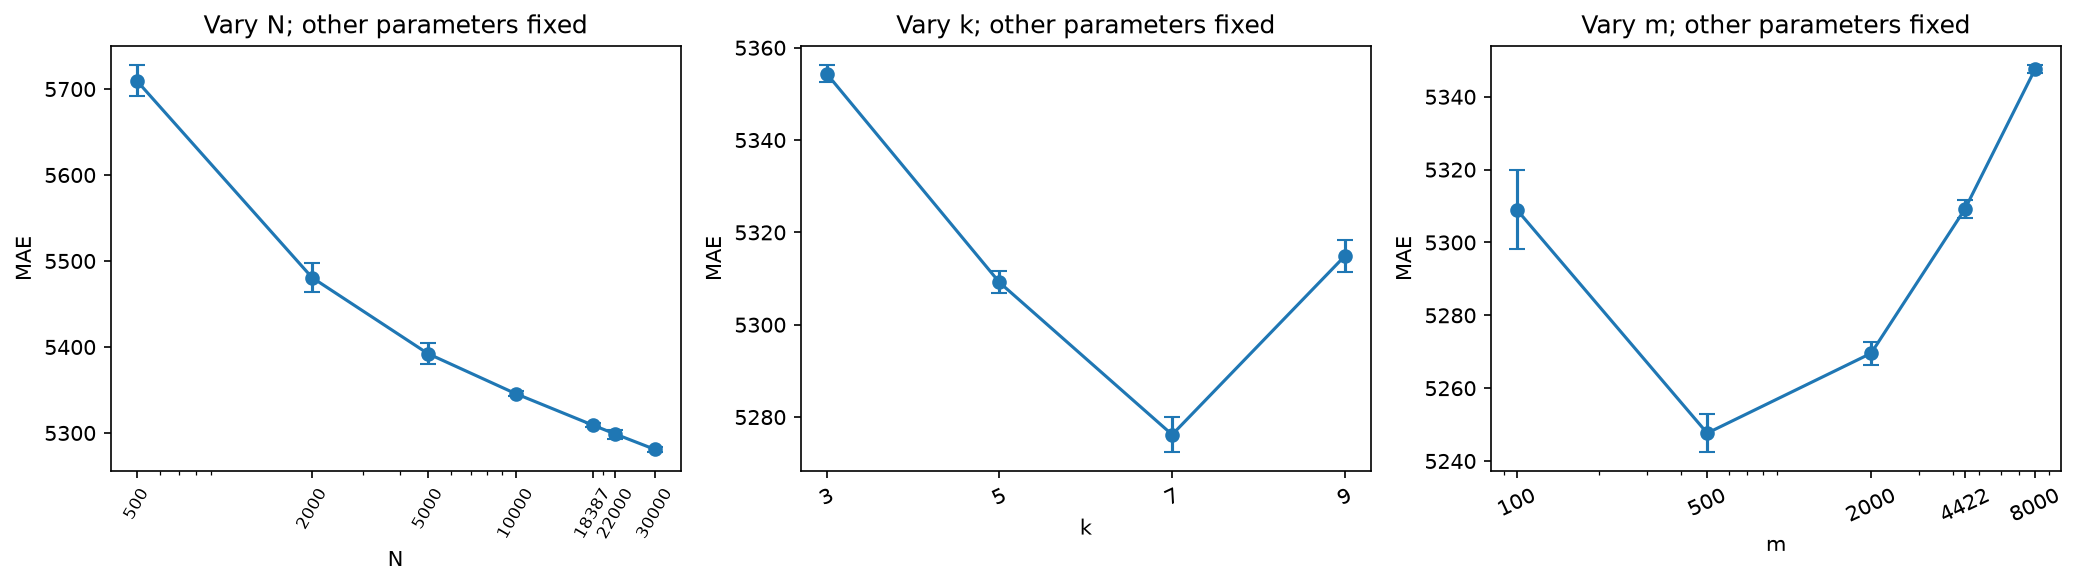

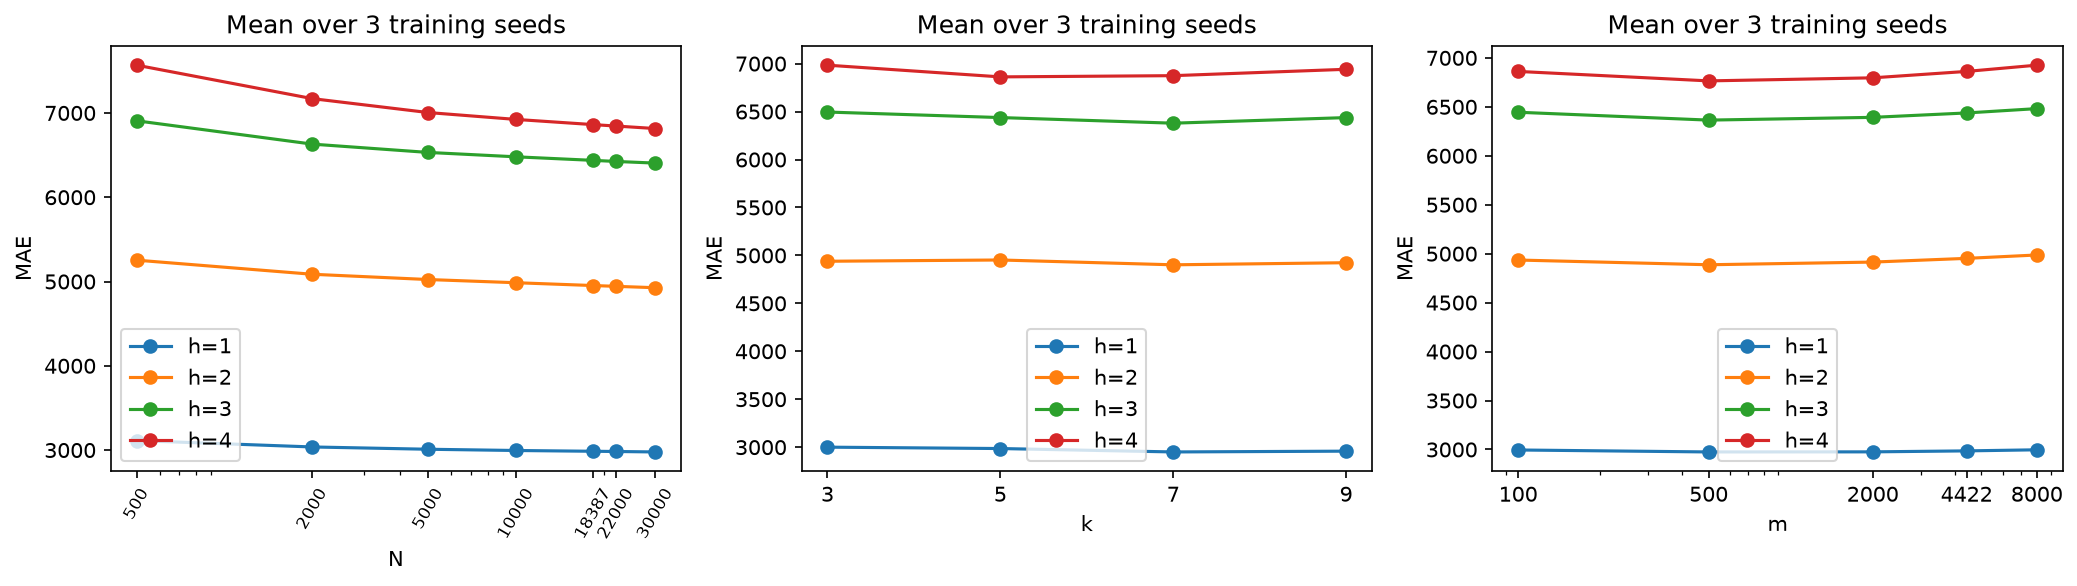

In [2]:
display(summary.loc[summary.sections.str.contains('E2.A'), ['N','k','m','MAE','MAE_seed_sd','RMSE','delta_MAE','delta_lo','delta_hi']])
figure('01_individual_mae')
figure('02_horizon_sensitivity')

Paired delta là MAE(config)−MAE(reference cùng seed), ghép chính xác state/origin/target/horizon. CI bootstrap theo bang, giữ origins/horizons/seeds cùng bang. Đọc cả mức thay đổi và độ bất định; không công bố một best row hậu nghiệm thành winner đã được xác nhận trên test độc lập.

## E2.B — Joint Parameter Interaction

Đủ 8 corners: N={1000,5000}, k={3,7}, m={500,2000}; center=(2000,5,1000), reference=(18387,5,4422) được giữ riêng.

Heatmaps chỉ có ô đã chạy và cùng color scale. Coded effect = 2 mean(product of ±1 signs × MAE). Pair difference-in-differences gấp đôi coded effect; triple interaction là exploratory, không phải kiểm định significance hoặc nhân quả.

,N,k,m,MAE,MAE_seed_sd
1,1000,3,500,5386.096633,16.892314
2,1000,3,2000,5498.521032,15.597840
3,1000,7,500,5333.144883,33.294225
4,1000,7,2000,5492.500164,0.788115
5,2000,5,1000,5351.789367,12.754061
7,5000,3,500,5349.706483,4.128725
8,5000,3,2000,5367.951700,9.410797
10,5000,7,500,5244.043950,8.474295
11,5000,7,2000,5315.560883,9.877294


,seed,term,order,effect,difference_in_differences
0,0,N,1,-103.237612,NaN
1,0,k,1,-75.366213,NaN
2,0,m,1,100.001087,NaN
3,0,N × k,2,-12.106337,-24.212675
4,0,N × m,2,-51.569237,-103.138473
5,0,k × m,2,34.470362,68.940725
6,0,N × k × m,3,-10.382462,NaN
7,1,N,1,-116.971224,NaN
8,1,k,1,-55.097675,NaN
9,1,m,1,88.762899,NaN


,seed,interaction,fixed_parameter,fixed_value,response_parameter,conditioning_parameter,effect_at_low,effect_at_high,difference_in_differences
0,0,N × m,k,3,m,N,106.717498,24.343950,-82.373548
1,0,N × m,k,7,m,N,196.423148,72.519750,-123.903398
2,0,N × k,m,500,k,N,-108.112700,-111.560450,-3.447750
3,0,N × k,m,2000,k,N,-18.407051,-63.384650,-44.977599
4,0,m × k,N,1000,k,m,-108.112700,-18.407051,89.705649
5,0,m × k,N,5000,k,m,-111.560450,-63.384650,48.175800
6,1,N × m,k,3,m,N,120.615498,15.299550,-105.315948
7,1,N × m,k,7,m,N,149.580147,69.556400,-80.023747
8,1,N × k,m,500,k,N,-40.688150,-111.117950,-70.429800
9,1,N × k,m,2000,k,N,-11.723501,-56.861100,-45.137599


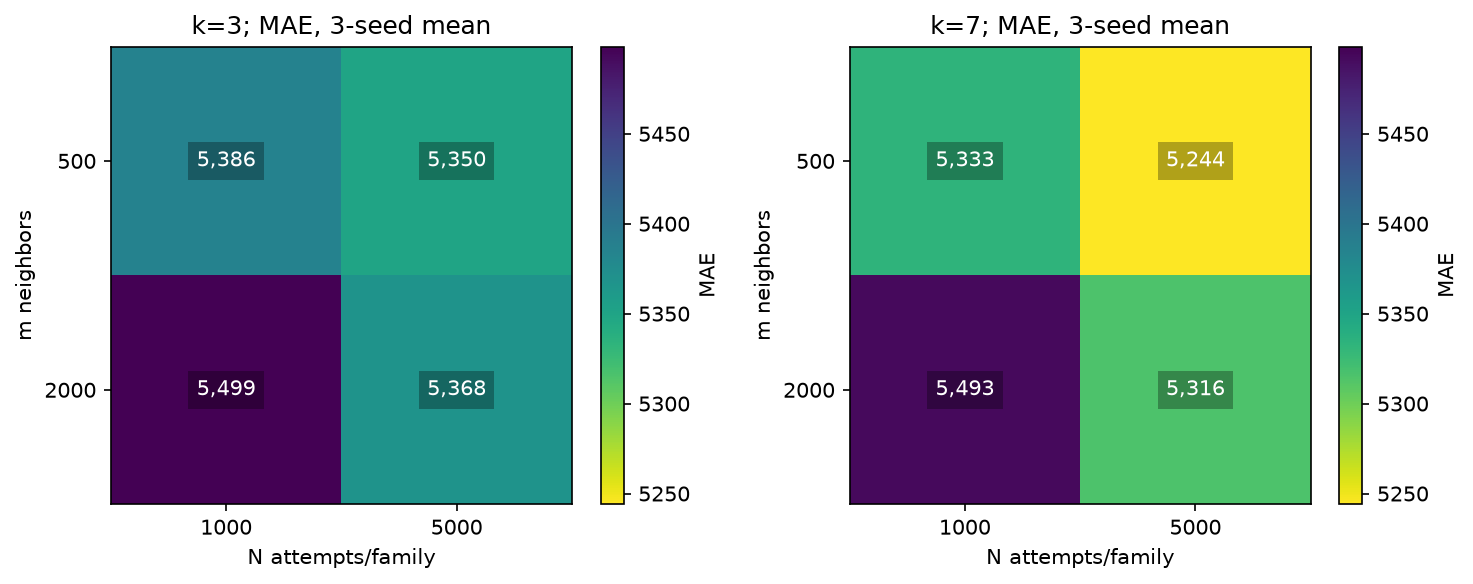

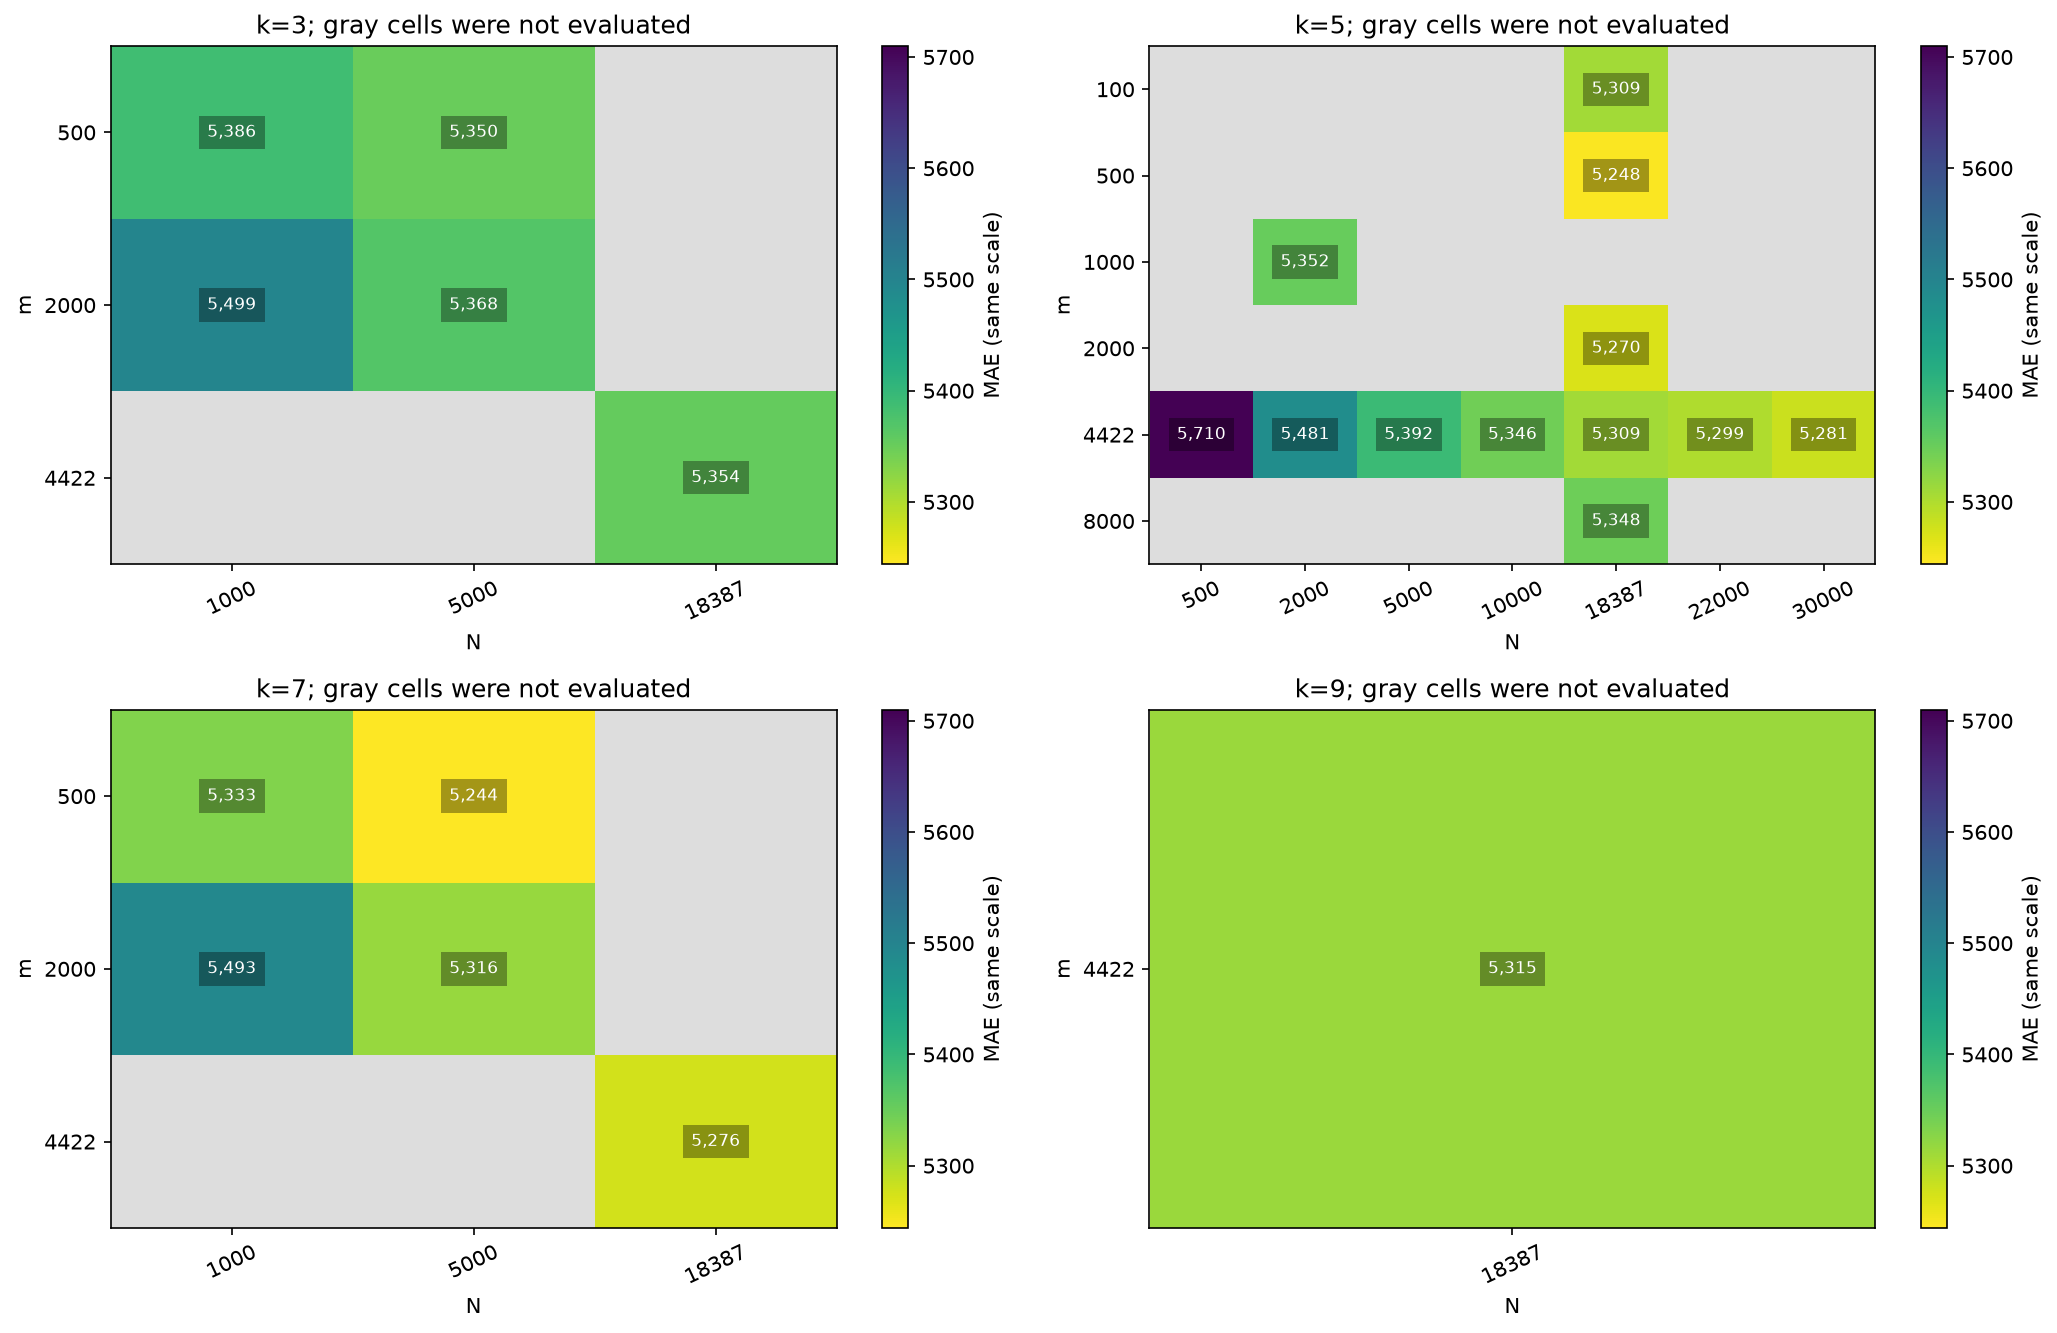

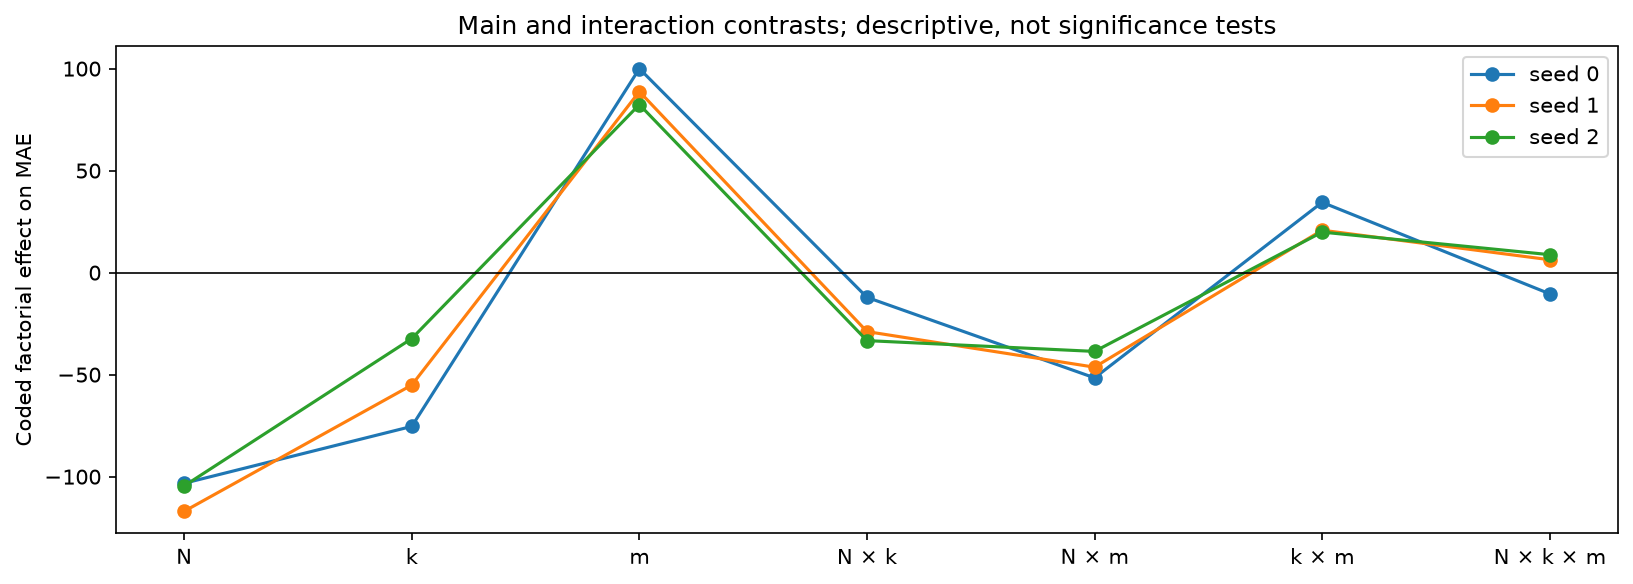

In [3]:
display(summary.loc[summary.sections.str.contains('factorial|center'), ['N','k','m','MAE','MAE_seed_sd']])
display(table('factorial_effects'))
display(table('conditional_interactions'))
figure('03_factorial_heatmaps')
figure('11_observed_grid_by_k')
figure('04_interaction_effects')

## E2.C — Accuracy, Stability and Computational Trade-offs

Stability đo MAE SD giữa ba banks và prediction SD/range trên cùng từng target. Chỉ có ba seeds nên chưa đánh giá đầy đủ tails của biến động giữa libraries.

Matching quality khác forecasting quality: với nested N, cùng k/query, minimum L1 không được tăng. MAE vẫn có thể tăng vì analogue quá khứ gần hơn không bảo đảm future tương tự. Raw L1/k cũng không làm geometry của các k trở nên hoàn toàn tương đương.

,N,k,m,MAE,MAE_seed_sd,prediction_seed_sd_mean,prediction_seed_range_mean
0,500,5,4422,5709.831075,17.923149,124.711279,237.330510
1,1000,3,500,5386.096633,16.892314,257.008075,491.187650
2,1000,3,2000,5498.521032,15.597840,160.768909,307.838251
3,1000,7,500,5333.144883,33.294225,284.936009,544.380500
4,1000,7,2000,5492.500164,0.788115,164.878901,313.508204
5,2000,5,1000,5351.789367,12.754061,234.960856,447.083950
6,2000,5,4422,5480.728332,16.488450,175.685735,331.366203
7,5000,3,500,5349.706483,4.128725,217.352216,415.009100
8,5000,3,2000,5367.951700,9.410797,139.488974,265.643200
9,5000,5,4422,5392.230733,11.948918,130.253817,248.677150


,seed,N,k,m,minimum_distance_mean,median_distance_mean,median_distance_per_difference_mean,increment_iqr_mean,mean_median_path_gap
0,0,500,5,4422,1484.018937,7881.151370,1576.230274,2122.594036,6830.240631
1,0,1000,3,500,226.428062,1542.228888,514.076296,2916.398503,4491.674570
2,0,1000,3,2000,226.428062,2437.519705,812.506568,2919.929265,5644.332839
3,0,1000,7,500,2784.386943,7277.125250,1039.589321,2450.962950,4499.375921
4,0,1000,7,2000,2784.386943,9500.022449,1357.146064,2502.734617,5980.496392
5,0,2000,5,1000,1079.955054,4247.870399,849.574080,2698.470625,5468.392485
6,0,2000,5,4422,1079.955054,5889.430441,1177.886088,2715.288826,7036.149163
7,0,5000,3,500,124.039029,902.674357,300.891452,2875.169000,4474.195767
8,0,5000,3,2000,124.039029,1436.179007,478.726336,2920.761725,4909.344220
9,0,5000,5,4422,926.472431,4823.601993,964.720399,2675.714675,5905.456630


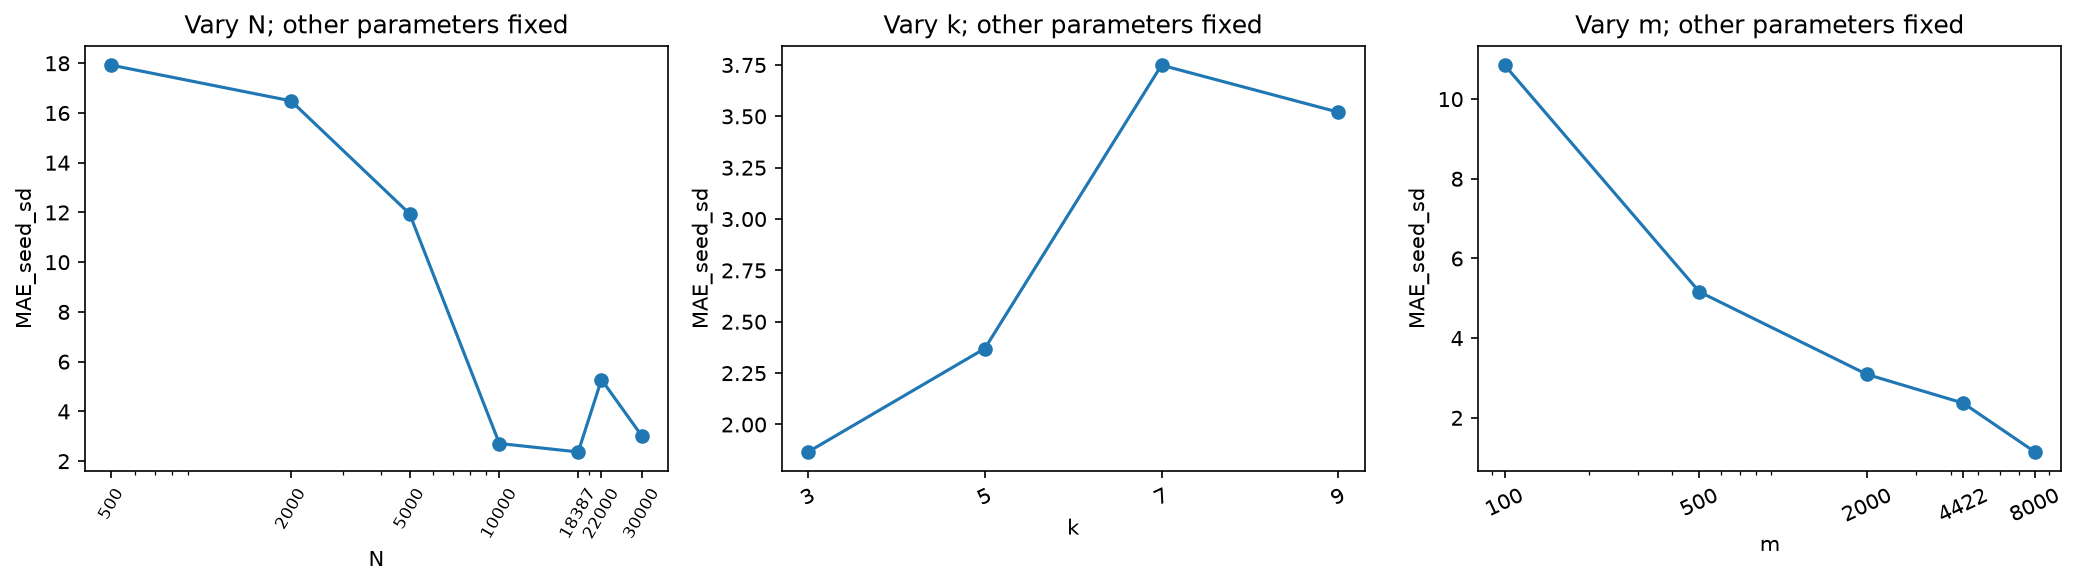

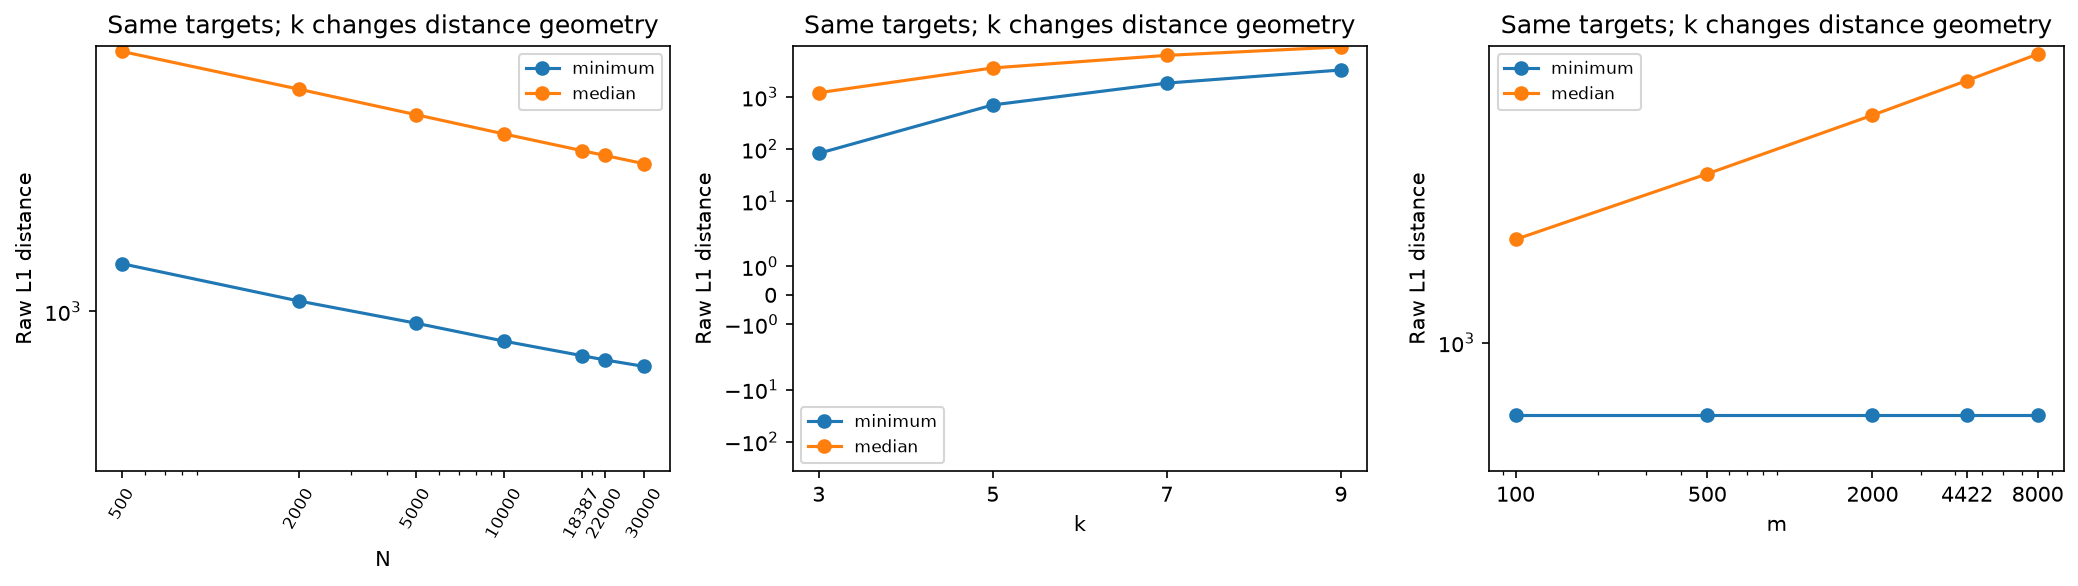

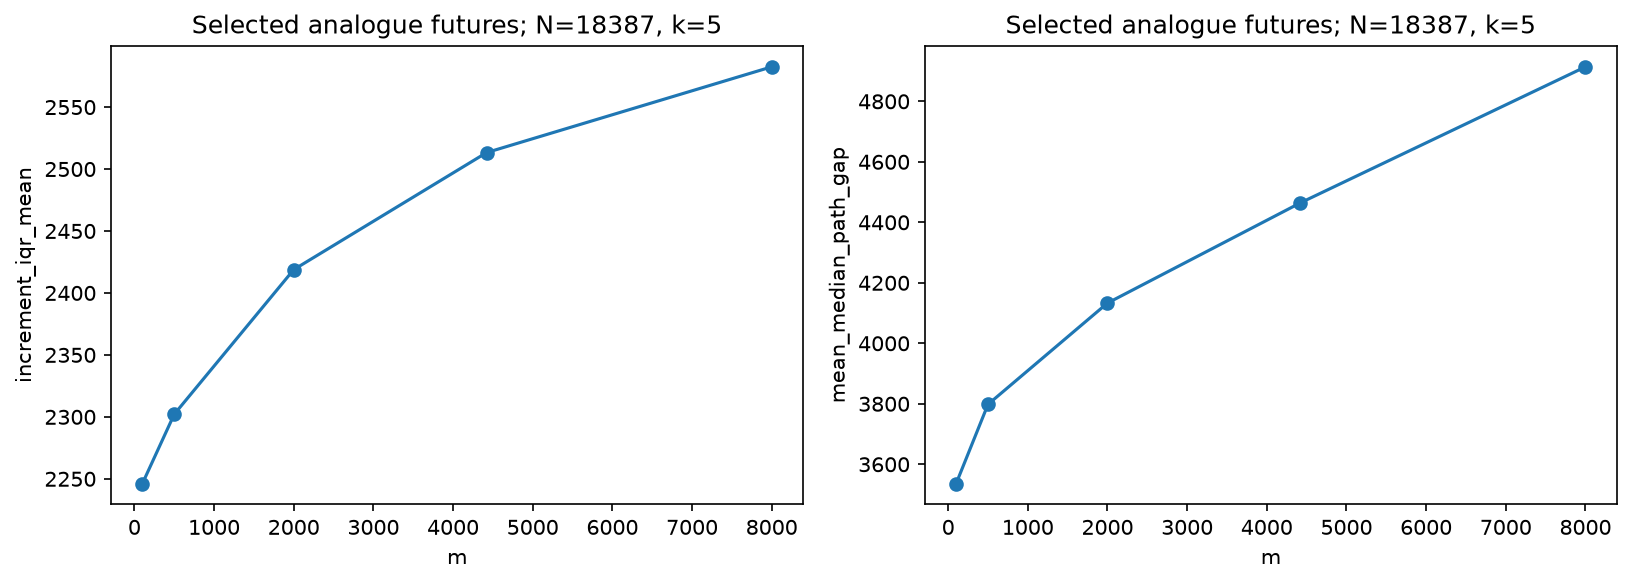

In [4]:
display(summary[['N','k','m','MAE','MAE_seed_sd','prediction_seed_sd_mean','prediction_seed_range_mean']])
display(table('matching_summary').head(20))
figure('05_seed_stability')
figure('06_matching_quality')
figure('09_aggregation_behavior')

### Runtime, generation và peak memory

Một group (seed,N,k) chạy trong subprocess riêng. Embedding/tree setup và maximum-m queries được dùng chung cho nhiều m; có benchmark riêng 32 queries cố định cho từng m. Estimated core latency cộng smoothing + per-m query benchmark + median aggregation, không phải measured wall time của cả job.

Peak RSS bao gồm load bank, embedding, KD tree, queries và diagnostics. Vì dùng chung maximum-m query, không gọi đó là peak memory riêng từng m. Không gồm generation worker RSS. Generation+export wall time lấy boundary timestamps của full bank; seed 0 là thời gian fresh replay. Prefix nhỏ được tái dùng, không có standalone generation timing giả.

,seed,accepted,attempts,generation_export_seconds,pack_seconds,full_replay_verified
0,0,54081,55161,108.892095,23.793123,True
1,1,54006,55161,135.648108,32.752488,False
2,2,54042,55161,134.516307,28.276625,False


,seed,N,accepted,added_attempts,added_accepted,generation_seconds
0,0,30000,88197,24000,23488,44.674986
1,0,22000,64709,10839,10628,21.031841
2,1,30000,88175,24000,23532,47.128412
3,1,22000,64643,10839,10637,20.759464
4,2,30000,88178,24000,23503,47.523078
5,2,22000,64675,10839,10633,21.655467


,seed,N,k,m,accepted_curves,M,embedding_seconds,index_seconds,shared_query_seconds,query_benchmark_mean_seconds,aggregation_seconds,peak_rss_bytes
0,0,10000,5,4422,29389,7053558,3.033352,3.073281,8.336479,0.004579,0.427482,870137856
1,0,1000,3,500,2935,694118,0.264531,0.149547,1.148102,0.000140,0.073615,330317824
2,0,1000,3,2000,2935,694118,0.264531,0.149547,1.148102,0.000483,0.203938,330317824
3,0,1000,7,500,2935,712525,0.274721,0.251942,17.965096,0.004929,0.076453,350388224
4,0,1000,7,2000,2935,712525,0.274721,0.251942,17.965096,0.008606,0.203943,350388224
...,...,...,...,...,...,...,...,...,...,...,...,...
64,2,5000,3,2000,14684,3433369,1.322863,1.066267,1.232393,0.000512,0.204827,562003968
65,2,5000,5,4422,14684,3485881,1.268341,1.365268,8.486843,0.005037,0.417584,627654656
66,2,5000,7,500,14684,3522591,1.439283,1.530551,28.883435,0.006736,0.076094,687587328
67,2,5000,7,2000,14684,3522591,1.439283,1.530551,28.883435,0.016096,0.205786,687587328


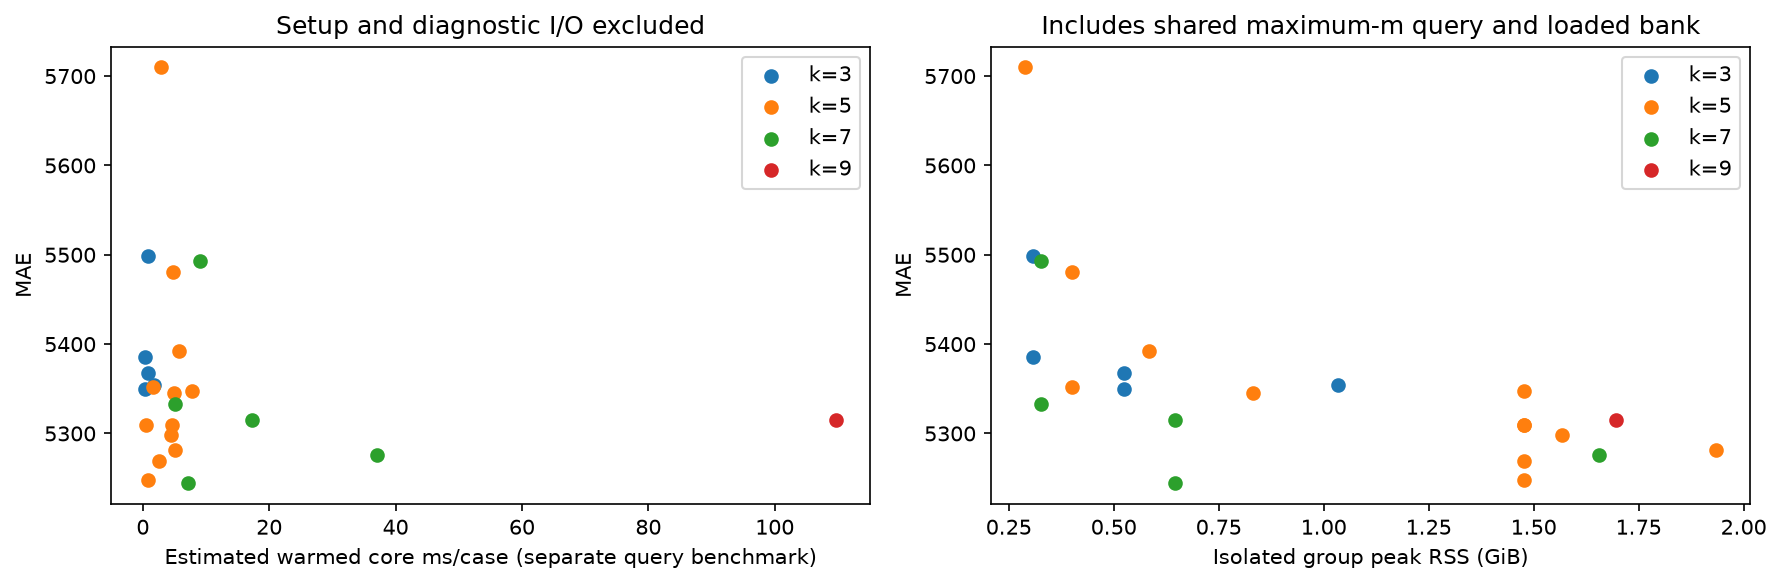

In [5]:
display(table('generation')[['seed','accepted','attempts','generation_export_seconds','pack_seconds','full_replay_verified']])
display(table('extension_generation')[['seed','N','accepted','added_attempts','added_accepted','generation_seconds']])
display(table('runtime')[['seed','N','k','m','accepted_curves','M','embedding_seconds','index_seconds','shared_query_seconds','query_benchmark_mean_seconds','aggregation_seconds','peak_rss_bytes']])
figure('07_accuracy_cost')

## Auxiliary analysis — Controlled Short-History Availability

Seed 0, N=18387, m=4422; first 16 genuine origins ×50 bang. Chỉ lộ last L=4/6/8/10 observations tại chính vintage đó. Không gọi đây là vintage có sớm hơn trong lịch.

Chỉ so k trong cùng L và cùng cases. Core GAM yêu cầu ít nhất 5 observations nên required history=max(k+1,5); L=4 không fit được ngay cả k=3. Không ép forecast, không fallback và không gộp auxiliary targets vào main scores.

,history_length,k,status,size
0,4,3,insufficient_history,800
1,4,5,insufficient_history,800
2,4,7,insufficient_history,800
3,4,9,insufficient_history,800
4,6,3,ok,800
5,6,5,ok,800
6,6,7,insufficient_history,800
7,6,9,insufficient_history,800
8,8,3,ok,800
9,8,5,ok,800


,history_length,k,targets,MAE,RMSE,bias,normalized_MAE
0,6,3,3200,2004.937344,5126.171887,133.495469,0.859177
1,6,5,3200,1919.414531,4782.574481,-163.512656,0.934490
2,8,3,3200,1968.779445,5010.791243,107.774837,0.869968
3,8,5,3200,1915.907251,4764.706244,-125.055146,0.973171
4,8,7,3200,1893.359743,4608.186173,-160.159502,1.065272
5,10,3,3200,1942.975156,4920.727041,73.737633,0.871370
6,10,5,3200,1908.140135,4655.753167,-128.741405,0.982032
7,10,7,3200,1895.587146,4560.301247,-151.896537,1.077380
8,10,9,3200,1935.373854,4605.135039,-158.812618,1.119926


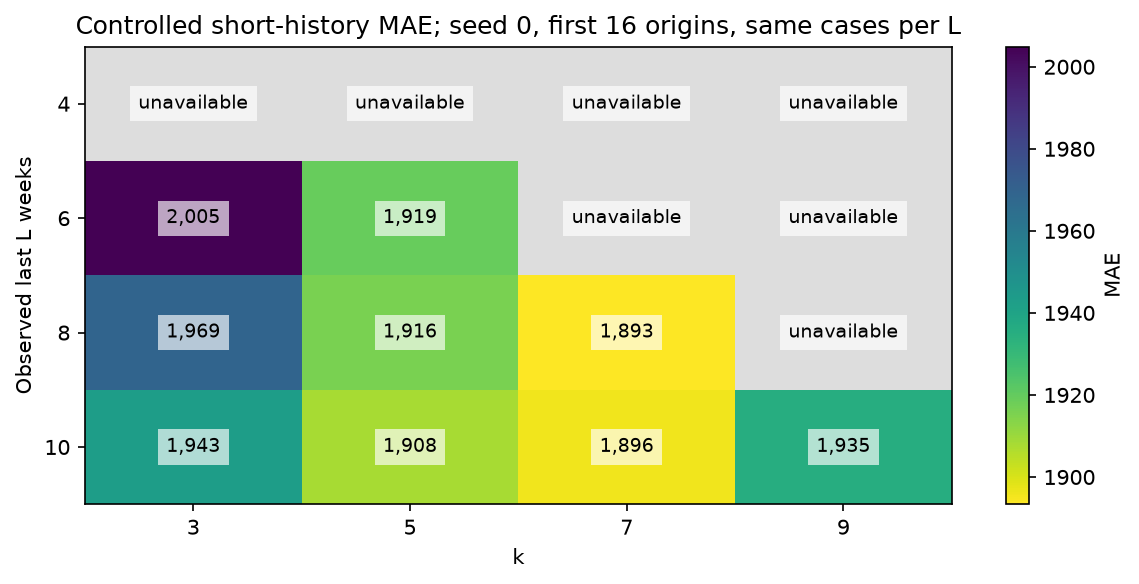

In [6]:
display(table('early_availability'))
display(table('early_metrics'))
figure('08_short_history')

### Numerical validity audit

Bộ lọc hiện hành **nonconstant_v2** loại history hoàn toàn phẳng bằng so sánh levels sau floor 1e-8, không dùng variance floating point. Notebook bắt buộc mọi group ghi đúng filter/source và retained constant rows =0. Thay k vẫn thay cả M và geometry; không diễn giải đây là tác động riêng window length với M cố định. Kết quả v1 được giữ riêng và không dùng để ép thứ hạng mới.

,seed,N,k,window_filter,M_core,constant_history_rows,constant_fraction,nonconstant_rows
0,0,10000,5,nonconstant_v2,7053558,0,0.0,7053558
1,0,1000,3,nonconstant_v2,694118,0,0.0,694118
2,0,1000,7,nonconstant_v2,712525,0,0.0,712525
3,0,18387,3,nonconstant_v2,12726896,0,0.0,12726896
4,0,18387,5,nonconstant_v2,12921078,0,0.0,12921078
5,0,18387,7,nonconstant_v2,13057937,0,0.0,13057937
6,0,18387,9,nonconstant_v2,13161144,0,0.0,13161144
7,0,2000,5,nonconstant_v2,1411061,0,0.0,1411061
8,0,22000,5,nonconstant_v2,15475361,0,0.0,15475361
9,0,30000,5,nonconstant_v2,21065458,0,0.0,21065458


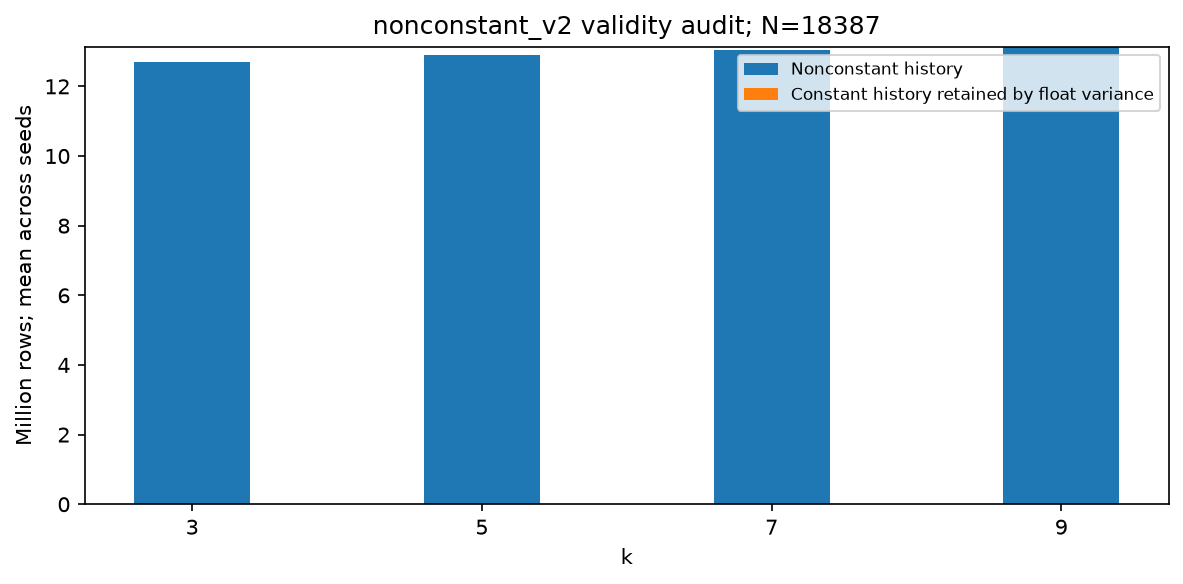

In [7]:
display(table('segment_validity_audit'))
figure('10_segment_validity')

## Nhận xét và tái lập

N là attempts, accepted curves và valid segments M được ghi riêng. k thay đổi M, chưa chạy equal-M ablation. Không dùng các kết quả COVID này để phản hồi BO. Python RNG/GAM chưa được xác minh numerical parity với R/mgcv.

Per-target forecasts và per-case matching ở groups/*.csv.gz, kèm completion checksums. Protocol/input/code hashes và source snapshot nằm trong output. Nhận xét dưới đây được sinh từ artifacts.

In [8]:
text = (OUT/'report.md').read_text()
display(Markdown(text.split('![')[0]))

# Experiment 2 — Individual sensitivity, interactions and trade-offs

23 configurations ×3 independent training banks ×10.000 common COVID targets = 690,000 point forecasts. GAM, exact L1, omit bridge; no BO or UQ rerun. The calendar is unchanged from Experiment 4.

Protocol v4, nonconstant_v2: exactly constant histories retained = 0. N=22000 and N=30000 remain the user-requested levels from the earlier study. Existing banks/prefixes are hash-verified and reused; forecasts are recomputed, not imported from v1. No levels are chosen again from COVID errors.

Reference (18387,5,4422): mean MAE 5,309.16, seed SD 2.37. E4 equality is checked only when its numerical source matches; a legacy E4 run is not a correctness oracle for the new filter.

## E2.A — Individual sensitivity

Each row changes one parameter; all other reference parameters remain fixed. Error bars show SD across three training seeds, not a confidence interval. COVID results are descriptive, not selection feedback.


### N

| N | MAE | MAE_seed_sd | RMSE | delta_MAE | delta_lo | delta_hi |
| --- | --- | --- | --- | --- | --- | --- |
| 500 | 5,709.831 | 17.923 | 22,971.141 | 400.672 | 197.801 | 667.320 |
| 2,000 | 5,480.728 | 16.488 | 21,732.478 | 171.569 | 75.952 | 313.144 |
| 5,000 | 5,392.231 | 11.949 | 21,101.275 | 83.072 | 34.515 | 154.508 |
| 10,000 | 5,345.723 | 2.709 | 20,804.861 | 36.564 | 14.229 | 66.027 |
| 18,387 | 5,309.159 | 2.370 | 20,634.964 | 0.000 | 0.000 | 0.000 |
| 22,000 | 5,298.695 | 5.280 | 20,610.462 | -10.464 | -17.118 | -4.593 |
| 30,000 | 5,280.970 | 3.028 | 20,572.777 | -28.189 | -46.061 | -10.781 |

Endpoint comparison for N: MAE 5,709.83 → 5,280.97. Check intermediate rows; accuracy need not be monotone.

### k

| k | MAE | MAE_seed_sd | RMSE | delta_MAE | delta_lo | delta_hi |
| --- | --- | --- | --- | --- | --- | --- |
| 3 | 5,354.357 | 1.866 | 20,386.083 | 45.198 | -4.440 | 98.710 |
| 5 | 5,309.159 | 2.370 | 20,634.964 | 0.000 | 0.000 | 0.000 |
| 7 | 5,276.189 | 3.749 | 20,569.813 | -32.970 | -78.364 | 12.584 |
| 9 | 5,314.885 | 3.520 | 20,698.076 | 5.726 | -48.028 | 60.062 |

Endpoint comparison for k: MAE 5,354.36 → 5,314.88. Check intermediate rows; accuracy need not be monotone.

### m

| m | MAE | MAE_seed_sd | RMSE | delta_MAE | delta_lo | delta_hi |
| --- | --- | --- | --- | --- | --- | --- |
| 100 | 5,308.982 | 10.853 | 20,760.228 | -0.177 | -65.242 | 76.616 |
| 500 | 5,247.653 | 5.162 | 20,556.060 | -61.505 | -110.197 | -8.077 |
| 2,000 | 5,269.578 | 3.088 | 20,564.498 | -39.581 | -66.875 | -13.046 |
| 4,422 | 5,309.159 | 2.370 | 20,634.964 | 0.000 | 0.000 | 0.000 |
| 8,000 | 5,347.533 | 1.143 | 20,789.896 | 38.374 | 16.662 | 67.491 |

Endpoint comparison for m: MAE 5,308.98 → 5,347.53. Check intermediate rows; accuracy need not be monotone.

Mean MAE increases in 0 of the 6 adjacent N expansions, although nearest matching distance never increases on these nested banks. This separates past matching quality from future forecasting quality.

Nested N check: 7,500 seed/state/origin queries, zero minimum-distance increase violations. This verifies matching coverage, not monotonic forecast accuracy.

Paired delta = configuration absolute error minus same-seed reference error. 95% percentile intervals resample whole states (1000 draws), keeping origins/horizons/seeds within state. They describe this panel; they do not establish nationwide independence or account for selecting a best row after viewing test.

## E2.B — Joint interactions

| N | k | m | MAE | MAE_seed_sd |
| --- | --- | --- | --- | --- |
| 1,000 | 3 | 500 | 5,386.097 | 16.892 |
| 1,000 | 3 | 2,000 | 5,498.521 | 15.598 |
| 1,000 | 7 | 500 | 5,333.145 | 33.294 |
| 1,000 | 7 | 2,000 | 5,492.500 | 0.788 |
| 2,000 | 5 | 1,000 | 5,351.789 | 12.754 |
| 5,000 | 3 | 500 | 5,349.706 | 4.129 |
| 5,000 | 3 | 2,000 | 5,367.952 | 9.411 |
| 5,000 | 7 | 500 | 5,244.044 | 8.474 |
| 5,000 | 7 | 2,000 | 5,315.561 | 9.877 |

| term | order | effect_mean | effect_seed_sd |
| --- | --- | --- | --- |
| N | 1 | -108.250 | 7.581 |
| N × k | 2 | -24.770 | 11.188 |
| N × k × m | 3 | 1.585 | 10.439 |
| N × m | 2 | -45.504 | 6.520 |
| k | 1 | -54.256 | 21.543 |
| k × m | 2 | 25.051 | 8.171 |
| m | 1 | 90.385 | 8.916 |

conditional_interactions.csv also reports each pairwise difference-in-differences separately at both levels of the third factor, so opposite conditional effects are not hidden by an average contrast.

Effects use coded factors ±1: 2×mean(sign product×MAE). A pairwise difference-in-differences is twice the listed coded interaction effect and is exported separately. Center/reference are not factorial corners. Three-way effects are exploratory; there are only eight corners and three seeds.

## E2.C — Stability, matching and computational cost

summary.csv includes seed SD of MAE and average per-target prediction SD/range. matching_summary.csv includes minimum/median L1, median L1/k, incremental IQR and mean-versus-median path differences. L1/k does not eliminate cross-k geometry differences.

runtime.csv reports accepted curves and valid segments M; prefix loading, embedding and tree setup; shared maximum-m query wall time; independent warmed 32-query benchmarks for each m; aggregation time and isolated group peak RSS. The estimated core time adds smoothing + per-m query benchmark + median aggregation; it is not measured end-to-end job time.

Peak RSS includes bank loading, embedding, KD tree, shared maximum-m work and diagnostics, so it is a group peak, not an independent per-m memory benchmark. Generation process/worker RSS is excluded. Disk scratch is removed after every group.

Prefix loading decompresses the full largest packed bank before selecting a nested subset; smaller-N peak RSS includes this common backing bank. Group wall time also includes diagnostic I/O and the auxiliary short-history study in seed0 full-N jobs. Use stage timings and separate per-m benchmarks rather than ranking seeds by total job time.

generation.csv reports actual largest-bank generation+CSV export duration using file timestamps at lock acquisition and metadata completion (imports excluded), plus packing time. Smaller N uses exact prefixes; no standalone smaller-N generation wall time is invented.

Generation timing for seed0 is a fresh complete replay, not the original historical duration. Seeds 1/2 were generated concurrently and seed0 replay alone; these wall times reflect different system load.

extension_generation.csv separately records each incremental extension and its generation duration (18387→22000→30000). Extended banks append new streams; original scalar family seeds are never shifted by changing N.

Minimum M across jobs: 342,947; every requested m (including 8000) is validated against its own library M before querying.

## Controlled short-history availability

Separate seed-0 analysis at first 16 genuine panel origins, exposing only last L=4/6/8/10 weekly observations. This is controlled data availability, not an earlier vintage. Unavailable k/L combinations remain explicit; no invalid forecast or fallback is forced. GAM core requires at least 5 observations, so even k=3 cannot run at L=4 without changing software.

## Limits

- N is attempts per family; seasonal rejections are retained and never replaced. All seed-level banks have the same largest-N family namespace; nested subsets select attempt indices, not first N accepted curves.
- k changes both required history and the number of valid segments M. No equal-M ablation is performed; both N and M are exported.
- Numerical core audit: seed0 reference retains 0 exactly constant-history windows. segment_validity_audit.csv records the filter for each N/k/seed: legacy numpy_variance_v1 may retain constant rows due to rounding; nonconstant_v2 excludes them exactly. Existing predictions are never relabelled as corrected runs. k effects also include the recorded filter's behavior.
- Common main origins have >=10 observations. Short-history results are separate and must only compare supported k within the same L.
- Population, wave phase and reporting zeros remain as in the fixed panel. This study does not repair data, infer causal parameter effects, or prove numerical equivalence with R/mgcv.
- RMSE in summary.csv is the mean of seed-specific RMSE; per-seed/horizon metrics are available separately. Three seeds give limited stability evidence.

